# The Composable API

Every functional generator has a class counterpart (`Step`, `Sinusoidal`, `OUProcess`, ...). Instead of an array, the class returns an **`Input` object**: a description of a signal that produces its array when called. Objects can be combined into new objects, which makes protocols easy to build from parts.

| Operation | Result |
|---|---|
| `a + b`, `a - b`, `a * b`, `a / b` | pointwise arithmetic; `b` may also be a number or quantity |
| `-a` | negation |
| `a & b` | `a` followed by `b` in time (`Sequential(a, b)`) |
| `a | b` | pointwise maximum |
| `a.scale(k)`, `a.clip(lo, hi)`, `a.apply(f)` | transform the values |
| `a.shift(t)` | delay (or advance, for negative `t`) within the same duration |
| `a.smooth(tau)` | first-order low-pass filter with time constant `tau` |
| `a.repeat(n)` | `a` played `n` times in a row |

## 1. Setup

In [1]:
import brainstate
import brainunit as u
import matplotlib.pyplot as plt
import numpy as np

import braintools.input as inp

brainstate.environ.set(dt=0.1 * u.ms)
dt_ms = 0.1


def t_of(x):
    return np.arange(len(x)) * dt_ms


def show(panels, ncols=2, height=2.2):
    nrows = int(np.ceil(len(panels) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, height * nrows), squeeze=False)
    for ax, (title, x) in zip(axes.flat, panels.items()):
        ax.plot(t_of(x), u.get_mantissa(x), lw=1)
        ax.set_title(title, fontsize=10)
    for ax in axes.flat[len(panels):]:
        ax.axis("off")
    for ax in axes[-1]:
        ax.set_xlabel("time (ms)")
    fig.tight_layout()
    plt.show()

## 2. Objects, Arrays, and Caching

Calling an `Input` generates its array once and caches it; later calls return the same array. For stochastic inputs this means one object always yields **the same realization** until you ask for a new one with `recompute=True`. Use separate objects (with different seeds) when you need independent noise.

In [2]:
noise = inp.OUProcess(mean=0.0, sigma=1.0, tau=5 * u.ms, duration=100 * u.ms)
first = noise()
print("second call returns the cached array:", bool(u.math.all(first == noise())))
print("recompute=True draws a new one:     ", not bool(u.math.all(first == noise(recompute=True))))

# The same object used twice is perfectly correlated with itself:
doubled = noise + noise
print("noise + noise == 2 * noise:", bool(u.math.allclose(doubled(), 2 * noise())))
independent = inp.OUProcess(0.0, 1.0, 5 * u.ms, 5000 * u.ms, seed=1) + inp.OUProcess(0.0, 1.0, 5 * u.ms, 5000 * u.ms, seed=2)
print(f"std of two independent processes summed: {float(np.std(independent())):.2f} (about sqrt(2))")

second call returns the cached array: True
recompute=True draws a new one:      True
noise + noise == 2 * noise: True


std of two independent processes summed: 1.47 (about sqrt(2))


## 3. Arithmetic

Arithmetic combines two inputs sample by sample; numbers and quantities are treated as constant inputs. If the operands have different durations, the shorter one is padded with zeros. Two details to keep in mind:

- **Division** treats zeros in the divisor as 1 (in the divisor's unit) instead of producing `inf`; with a dimensionless divisor this keeps the numerator. This also covers the zero padding of a shorter divisor.
- Units follow the usual rules: `nA + pA` is converted, `nA * dimensionless` stays in nA, `nA + mV` raises an error.

unit: nA, peak 1.488 nA (1 + 0.5)
short + long: 3000 samples; value 2 in the first 100 ms, then 1.0
3 / 0 -> 3.0 (numerator kept)
3 nA / 2 mV -> 1.5 uS


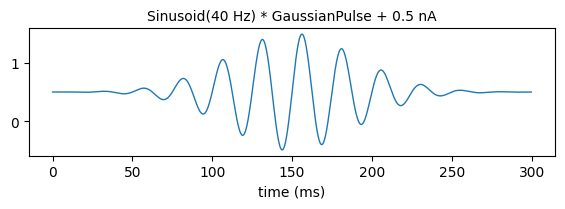

In [3]:
carrier = inp.Sinusoidal(1.0 * u.nA, 40 * u.Hz, 300 * u.ms)
envelope = inp.GaussianPulse(1.0, center=150 * u.ms, sigma=40 * u.ms, duration=300 * u.ms)
offset = inp.Constant([(0.5 * u.nA, 300 * u.ms)])

modulated = carrier * envelope + offset
print(f"unit: {u.get_unit(modulated())}, peak {float(modulated().max().to_decimal(u.nA)):.3f} nA (1 + 0.5)")

short = inp.Constant([(1.0, 100 * u.ms)])
long = inp.Constant([(1.0, 300 * u.ms)])
padded = (short + long)()
print(f"short + long: {padded.shape[0]} samples; value 2 in the first 100 ms, then {float(padded[-1])}")

ratio = (inp.Constant([(3.0, 10 * u.ms)]) / inp.Constant([(0.0, 10 * u.ms)]))()
print(f"3 / 0 -> {float(ratio[0])} (numerator kept)")
conductance = (inp.Constant([(3.0 * u.nA, 10 * u.ms)]) / inp.Constant([(2.0 * u.mV, 10 * u.ms)]))()
print(f"3 nA / 2 mV -> {conductance[0]}")

show({"Sinusoid(40 Hz) * GaussianPulse + 0.5 nA": modulated()}, ncols=1)

## 4. Combining in Time: `&` and `|`

`a & b` plays `b` after `a`, so durations add. This is the natural way to write a protocol as a list of phases. `a | b` keeps the larger of the two values at every sample.

total duration 600 ms, 6000 samples


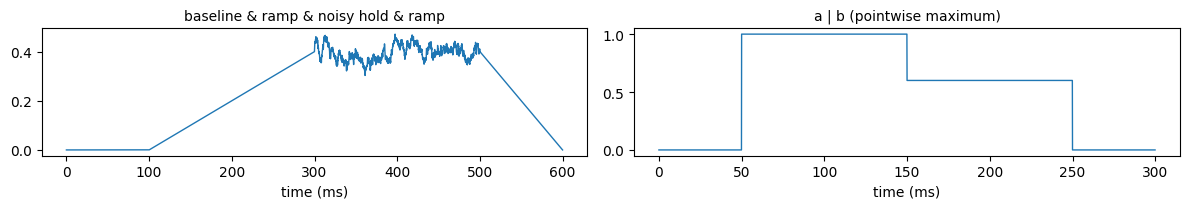

In [4]:
baseline = inp.Constant([(0.0 * u.nA, 100 * u.ms)])
ramp_up = inp.Ramp(0.0 * u.nA, 0.4 * u.nA, 200 * u.ms)
hold = inp.Constant([(0.4 * u.nA, 200 * u.ms)]) + inp.OUProcess(0.0 * u.nA, 0.03 * u.nA, 5 * u.ms, 200 * u.ms, seed=0)
ramp_down = inp.Ramp(0.4 * u.nA, 0.0 * u.nA, 100 * u.ms)

protocol = baseline & ramp_up & hold & ramp_down
print(f"total duration {protocol.duration}, {protocol().shape[0]} samples")

a = inp.Step([0.0, 1.0, 0.0], [0, 50, 150] * u.ms, 300 * u.ms)
b = inp.Step([0.0, 0.6, 0.0], [0, 100, 250] * u.ms, 300 * u.ms)
show({"baseline & ramp & noisy hold & ramp": protocol(), "a | b (pointwise maximum)": (a | b)()})

## 5. Transformations

- `scale(k)` multiplies by `k`; `clip(lo, hi)` bounds the values (either bound may be `None`); `apply(f)` applies any function to the generated array.
- `shift(t)` moves the signal by `t` **within the same duration**: a delay inserts zeros at the start and drops the end, an advance does the opposite.
- `smooth(tau)` is the first-order low-pass $y_i = y_{i-1} + \frac{dt}{\tau}(x_i - y_{i-1})$, so a unit step reaches $1 - e^{-1} \approx 0.632$ about `tau` after it starts.
- `repeat(n)` concatenates `n` copies.

shift(30 ms): pulse now from 50 to 90 ms, length still 1000 samples
smooth(10 ms) at 10 ms after the step: 0.638 (1 - exp(-1) = 0.632)
clip(0, None) min 0.00; apply(x**2) mean 0.500 (0.5)
repeat(3): 3000 samples


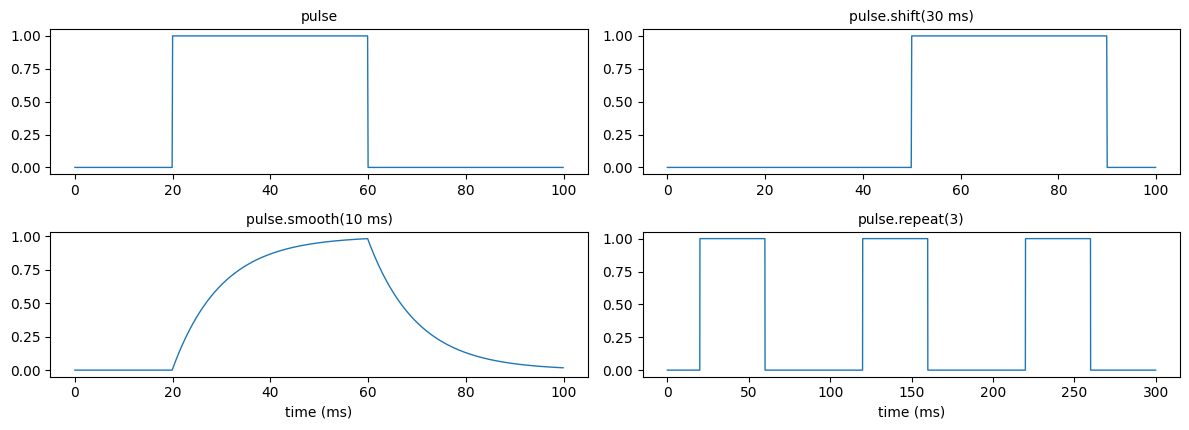

In [5]:
pulse = inp.Step([0.0, 1.0, 0.0], [0, 20, 60] * u.ms, 100 * u.ms)

delayed = pulse.shift(30 * u.ms)()
on = np.flatnonzero(np.asarray(delayed)) * dt_ms
print(f"shift(30 ms): pulse now from {on[0]:.0f} to {on[-1] + dt_ms:.0f} ms, length still {delayed.shape[0]} samples")

smoothed = pulse.smooth(10 * u.ms)()
print(f"smooth(10 ms) at 10 ms after the step: {float(smoothed[300]):.3f} (1 - exp(-1) = {1 - np.exp(-1):.3f})")

wave = inp.Sinusoidal(1.0, 10 * u.Hz, 100 * u.ms)
rectified = wave.clip(0.0, None)
squared = wave.apply(lambda x: x ** 2)
print(f"clip(0, None) min {float(rectified().min()):.2f}; apply(x**2) mean {float(squared().mean()):.3f} (0.5)")
print(f"repeat(3): {pulse.repeat(3)().shape[0]} samples")

show({"pulse": pulse(), "pulse.shift(30 ms)": delayed, "pulse.smooth(10 ms)": smoothed,
      "pulse.repeat(3)": pulse.repeat(3)()})

## 6. Multiple Channels

Stochastic inputs accept `n` for independent channels and return shape `(steps, n)`. A single-channel input combines with a multi-channel one by broadcasting over the channels, for example to add a common stimulus to independent noise:

common (2000,) + private (2000, 5) -> (2000, 5)


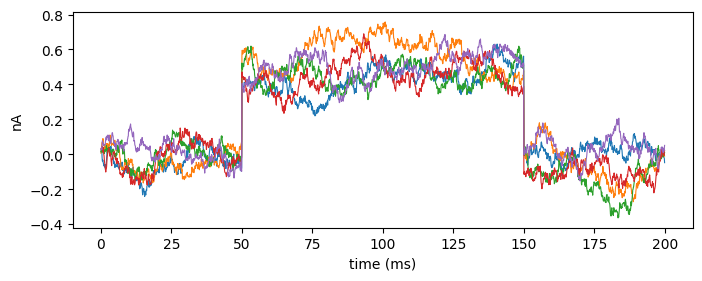

In [6]:
common = inp.Step([0.0, 0.5, 0.0] * u.nA, [0, 50, 150] * u.ms, 200 * u.ms)
private = inp.OUProcess(0.0 * u.nA, 0.1 * u.nA, 10 * u.ms, 200 * u.ms, n=5, seed=0)
drive = (common + private)()
print(f"common {common().shape} + private {private().shape} -> {drive.shape}")

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(t_of(drive), drive.to_decimal(u.nA), lw=0.8)
ax.set_xlabel("time (ms)")
ax.set_ylabel("nA")
plt.show()

## 7. Families of Protocols

Because inputs are objects, a family of protocols is just a list built in a loop or comprehension. Here are the current steps of an F-I (frequency-current) experiment, driving the leaky integrate-and-fire neuron from the introduction (vectorized over all amplitudes at once).

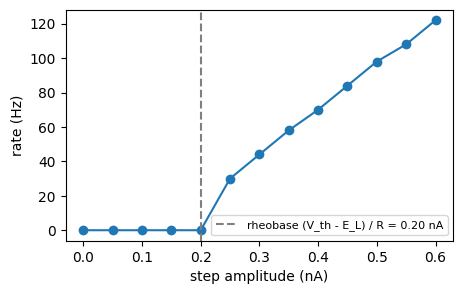

first amplitude that fires: 0.25 nA


In [7]:
amplitudes = np.linspace(0.0, 0.6, 13) * u.nA
family = [inp.Constant([(0 * u.nA, 50 * u.ms), (a, 500 * u.ms), (0 * u.nA, 50 * u.ms)]) for a in amplitudes]
I = u.math.stack([f() for f in family], axis=1)  # (steps, 13)

tau, R, E_L, V_th = 20 * u.ms, 100 * u.Mohm, -70 * u.mV, -50 * u.mV
dt = brainstate.environ.get_dt()
V = u.math.full(I.shape[1], -70.0) * u.mV
counts = np.zeros(I.shape[1], dtype=int)
for I_t in I:
    V = V + dt / tau * (-(V - E_L) + R * I_t)
    fired = np.asarray(V >= V_th)
    counts += fired
    V = u.math.where(fired, E_L, V)
rate = counts / 0.5  # spikes per second during the 500 ms step

rheobase = (V_th - E_L) / R
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(amplitudes.to_decimal(u.nA), rate, "o-")
ax.axvline(rheobase.to_decimal(u.nA), ls="--", color="0.5", label=f"rheobase (V_th - E_L) / R = {rheobase.to_decimal(u.nA):.2f} nA")
ax.set_xlabel("step amplitude (nA)")
ax.set_ylabel("rate (Hz)")
ax.legend(fontsize=8)
plt.show()
print("first amplitude that fires:", amplitudes[np.argmax(rate > 0)])

## Summary

- Composable classes return `Input` objects; calling one generates and caches its array (`recompute=True` redraws stochastic inputs).
- Reusing the same stochastic object reuses the same noise; create separate objects for independent noise.
- `+ - * /` combine sample by sample with zero padding; division treats a zero divisor as 1.
- `&` concatenates in time, `|` takes the maximum; `shift` keeps the duration; `smooth(tau)` is a first-order low-pass.
- Single-channel inputs broadcast over multi-channel ones.